# Issue #6 · v2 calibration support and nested Raw / Adaptive pilots

Run notebook 01 first. The frozen issue #5 protocol supplies **training pool** and
**calibration** roles. This notebook never decodes development-validation or final-test
images, runs a detector, or trains a model. It creates immutable nested **S10/S20**
(and optional S40) manifests, then exports **S10 only** by default as two paired branches.

Raw and Adaptive both decode the original and encode JPEG quality 95. Geometry and
native-converted annotations are identical. Policy calibration uses a seeded sample of
**calibration only**, fits bounded quantile thresholds, and compares two mild strengths
per operator against skip on at most 12 routed images. Recipe freeze precedes pilot
quality inspection. Quality proxies are **not detection accuracy**; no AP claim follows.
Use a fresh version/root for changed IDs, code, policy, sample or JPEG settings.

This is the v2 rerun after PR review. The original executed v1 notebook, including
all charts and example images, is preserved byte-for-byte in
[`evidence/02_adaptive_preprocessing_v1.ipynb`](evidence/02_adaptive_preprocessing_v1.ipynb).
V1 datasets and reports remain unchanged. Current policy code requires fresh v2 roots.

In [1]:
import gzip
import os
import platform
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from IPython.utils.capture import capture_output

from vehicle_detection.adaptive import (
    METRICS,
    calibrate_policy,
    export_pair,
    freeze_policy,
    paired_quality,
    validate_policy,
)
from vehicle_detection.common import file_hash, read_image, read_json, write_json
from vehicle_detection.data import CLASSES, convert_labels, scan_bdd
from vehicle_detection.offline import estimate_disk, verify_alignment
from vehicle_detection.protocol import validate_protocol
from vehicle_detection.subsets import build_subsets, freeze_subsets, training_records

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_ROOT = ROOT / "data/bdd100k"
RUN_ROOT = ROOT / "runs/issue6-v2"
REPORT_ROOT = ROOT / "docs/issue6-v2"
PROTOCOL_PATH = ROOT / "runs/issue5-v1/protocol.json"
SEED, ATTEMPTS = 2026, 128
INCLUDE_S40 = False
EXPORT_SUBSET = "S10"  # S20 is a manifest only until a later scaling decision.
CALIBRATION_SAMPLE, PER_OPERATOR, MIN_SUPPORT = 256, 12, 12
RUN_ROOT.mkdir(parents=True, exist_ok=True)
REPORT_ROOT.mkdir(parents=True, exist_ok=True)
cv2.setNumThreads(1)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
protocol = validate_protocol(read_json(PROTOCOL_PATH))
print("Frozen parent:", protocol["manifest_id"])
print("No detector, training, development or final-test image access in this notebook.")

Frozen parent: 680090b8eef098fbe10c77e632aacbfd3d6854d8489d7518e20f062e032b6e44
No detector, training, development or final-test image access in this notebook.


## Freeze nested, representative image-ID subsets

Search 128 seeded whole-group orders for minimum combined S10/S20 drift in class image
presence and instances, negatives, object sizes, weather, time, scene, their intersections
and class × condition support. Prefixes enforce nesting; whole groups can move nominal
image percentages. The full training pool is the only selection reference. Rare/zero
strata are disclosed, never manufactured by oversampling. Inferred sequence grouping
and duplicate safeguards inherit the limitations of issue #5.

In [2]:
subsets = build_subsets(protocol, seed=SEED, attempts=ATTEMPTS, include_s40=INCLUDE_S40)
freeze_subsets(RUN_ROOT / "subsets.json", subsets, protocol)
pool = protocol["splits"]["training_pool"]
counts = pd.DataFrame(
    {
        "training_pool": protocol["summaries"]["training_pool"],
        **{k: v["summary"] for k, v in subsets["subsets"].items()},
    }
).fillna(0)
display(counts.loc[["images", "negative", *[f"presence:{c}" for c in CLASSES]]].T)
print("Subset identity:", subsets["manifest_id"])
display(
    pd.DataFrame(
        [
            {
                "subset": k,
                "groups": len(v["groups"]),
                "target_fraction": v["target_fraction"],
                "actual_fraction": v["actual_fraction"],
            }
            for k, v in subsets["subsets"].items()
        ]
    )
)
audit = pd.DataFrame(subsets["diagnostics"])
audit.to_csv(REPORT_ROOT / "subset_support.csv", index=False)
display(audit[audit.rare_support].sort_values(["feature", "subset"]))
display(audit.assign(abs_drift=audit.delta_per_image.abs()).nlargest(15, "abs_drift"))
print("\n".join(subsets["limitations"]))

,images,negative,presence:car,presence:truck,presence:bus,presence:train,presence:motorcycle,presence:bicycle
training_pool,48903.0,397.0,48344.0,13199.0,6298.0,75.0,1610.0,3046.0
S10,4890.0,34.0,4841.0,1289.0,622.0,5.0,168.0,307.0
S20,9781.0,73.0,9683.0,2605.0,1225.0,11.0,339.0,639.0


Subset identity: 8a9ba46aa120f0e1d113d4bd907bc8ef5e82ab9bb3bd533d863812deb3f30b4f


,subset,groups,target_fraction,actual_fraction
0,S10,2974,0.1,0.099994
1,S20,5915,0.2,0.200008


,subset,feature,support,pool_support,expected,delta_per_image,rare_support,zero_support
8,S10,intersection:clear|dawn/dusk|gas stations,0,3,0.299982,-0.000061,True,True
358,S20,intersection:clear|dawn/dusk|gas stations,0,3,0.600025,-0.000061,True,True
10,S10,intersection:clear|dawn/dusk|parking lot,1,7,0.699957,0.000061,True,False
360,S20,intersection:clear|dawn/dusk|parking lot,3,7,1.400057,0.000164,True,False
13,S10,intersection:clear|daytime|gas stations,1,6,0.599963,0.000082,True,False
...,...,...,...,...,...,...,...,...
653,S20,joint_presence:truck|scene:tunnel,2,21,4.200172,-0.000225,True,False
308,S10,joint_presence:truck|timeofday:undefined,2,22,2.199865,-0.000041,True,False
658,S20,joint_presence:truck|timeofday:undefined,2,22,4.400180,-0.000245,True,False
310,S10,joint_presence:truck|weather:foggy,1,17,1.699896,-0.000143,True,False


,subset,feature,support,pool_support,expected,delta_per_image,rare_support,zero_support,abs_drift
169,S10,joint_instances:car|weather:clear,25778,261701,26168.494571,-0.079856,False,False,0.079856
173,S10,joint_instances:car|weather:rainy,3722,33834,3383.192442,0.069286,False,False,0.069286
166,S10,joint_instances:car|timeofday:daytime,28310,279954,27993.682596,0.064687,False,False,0.064687
172,S10,joint_instances:car|weather:partly cloudy,3532,38440,3843.764186,-0.063755,False,False,0.063755
174,S10,joint_instances:car|weather:snowy,3960,36847,3684.473959,0.056345,False,False,0.056345
158,S10,joint_instances:car|scene:city street,31645,313717,31369.775474,0.056283,False,False,0.056283
3,S10,instances:car,50180,499153,49912.237900,0.054757,False,False,0.054757
175,S10,joint_instances:car|weather:undefined,5804,55587,5558.358996,0.050233,False,False,0.050233
353,S20,instances:car,100236,499153,99834.682801,0.041030,False,False,0.041030
517,S20,joint_instances:car|timeofday:night,36290,179458,35893.067869,0.040582,False,False,0.040582


BDD filename prefixes are inferred sequence safeguards, not verified video IDs.
Equal dHash groups candidates only; nonzero-distance near duplicates may remain.
Final-test pixels are unopened; cross-official content duplicates are unverified.
Val geometry uses the BDD2018 1280x720 annotation canvas, not decoded headers.
Rare supports below 5 use parent-marginal reporting; absent classes remain absent.
Percentages approximate image counts; groups are never split.
Rare support <5 requires parent-marginal reporting, not oversampling.


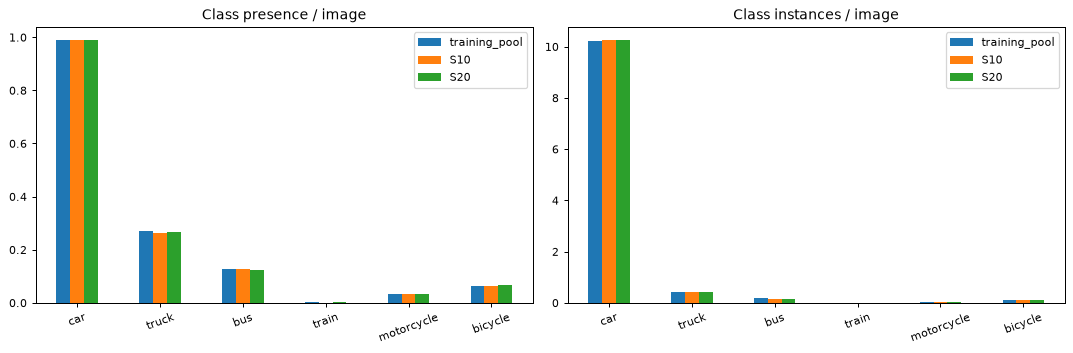

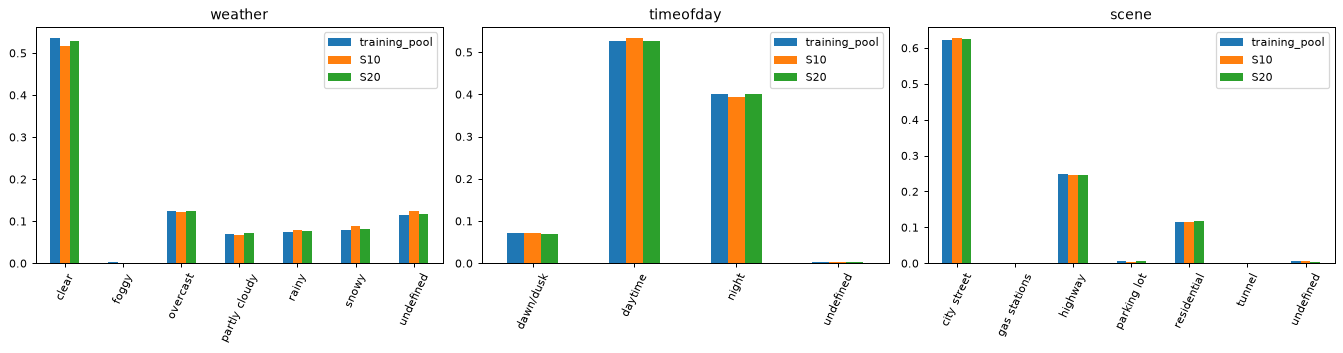

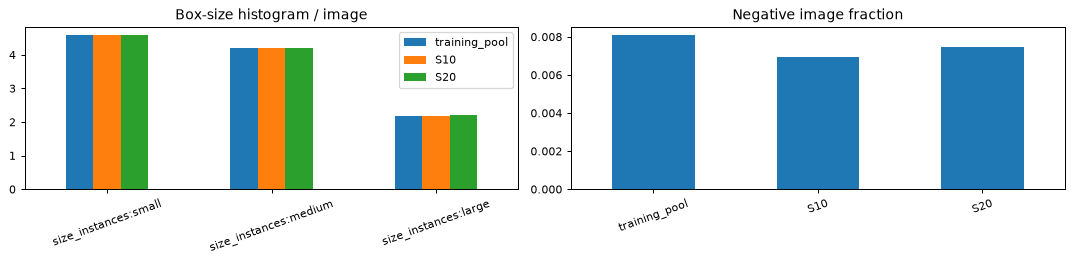

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, prefix in zip(axes, ["presence", "instances"], strict=True):
    data = counts.reindex([f"{prefix}:{c}" for c in CLASSES], fill_value=0)
    data.index = CLASSES
    data.div(counts.loc["images"]).plot.bar(ax=ax, title=f"Class {prefix} / image", rot=20)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "class_support.png")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, axis in zip(axes, ["weather", "timeofday", "scene"], strict=True):
    data = counts.loc[[k for k in counts.index if k.startswith(axis + ":")]]
    data.index = data.index.str.split(":", n=1).str[1]
    data.div(counts.loc["images"]).plot.bar(ax=ax, title=axis, rot=65)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "conditions.png")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
counts.reindex([f"size_instances:{s}" for s in ["small", "medium", "large"]], fill_value=0).div(
    counts.loc["images"]
).plot.bar(ax=axes[0], title="Box-size histogram / image", rot=20)
counts.loc[["negative"]].div(counts.loc["images"]).T.plot.bar(
    ax=axes[1], title="Negative image fraction", legend=False, rot=20
)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "sizes_negatives.png")
plt.show()

## Calibrate on calibration only, then freeze

Metrics are measured with a maximum 512-pixel side, matching the existing operators.
Thresholds use the 20th percentile of brightness/contrast/sharpness and the 90th of noise,
clamped to conservative bounds. Gamma candidates are 0.95/0.85; CLAHE clip 1.2/1.5,
grid 8; denoise strength 2/3; sharpen amount 0.15/0.3, sigma 1. At most **one** filter
runs: Gamma → CLAHE → Denoise → Sharpen, else skip. Combinations are deferred.

For each route, enumerate **all** eligible cases in the seeded calibration sample,
then select up to 12 by seeded uniform sampling rather than taking the first IDs.
A minimum of **12 candidate images** is required before fitting strengths; otherwise
the route is **uncalibrated and disabled**. Supported routes select a strength with
lower mean proxy loss than skip, or choose a proxy-calibrated skip. The minimum is
an engineering gate, not a statistical adequacy guarantee.
Loss penalizes dark/flat/noisy/very soft images and near-black/white saturation; inspect
`proxy_loss()` for exact weights. Compare candidate and Raw **after the same JPEG95
roundtrip**. These weights and small samples are heuristic, not supervised detector
optimization. Aggregate improvement can hide texture loss, halos, amplified noise or
washed-out night scenes. Unsupported routes remain disabled. No development outcomes
are read to choose thresholds, strengths or loss weights.

The median-residual noise proxy is unchanged and explicitly **unvalidated**.
Record its zero count, maximum and initial routing threshold; do not infer denoising
calibration from a collapsed distribution. A better estimator requires separate
validation and another policy version. This run does not make that claim.

Frozen policy before pilot inspection: 1ac3fb9bb94b132f70d3e168b5ef15a54b616444e535b9a3bb265682a6fce0ef


{'raw': {},
 'gamma': {'gamma': 0.85},
 'clahe': {'clip_limit': 1.2, 'grid_size': 8},
 'denoise': {'strength': 2.0},
 'sharpen': {'amount': 0.15, 'sigma': 1.0},
 'adaptive': {'brightness_below': 0.12,
  'contrast_below': 0.0,
  'noise_above': 1.0,
  'sharpness_min': 0.0,
  'sharpness_below': 0.0,
  'max_filters': 1}}

,eligible_count,candidate_count,minimum_support,status
gamma,65,12,12,proxy_calibrated_filter
clahe,5,5,12,uncalibrated_insufficient_support
denoise,0,0,12,uncalibrated_insufficient_support
sharpen,0,0,12,uncalibrated_insufficient_support


{'status': 'unvalidated_proxy',
 'sample_count': 256,
 'zero_count': 229,
 'maximum': 0.011628076434135437,
 'initial_routing_threshold': 0.035}

,operator,settings,ids,mean_proxy_loss_delta
0,gamma,{'gamma': 0.95},"[114e578a-47a24858, 3bfe7892-1d89aa18, 3e27639...",-0.011388
1,gamma,{'gamma': 0.85},"[114e578a-47a24858, 3bfe7892-1d89aa18, 3e27639...",-0.149158
2,clahe,"{'clip_limit': 1.2, 'grid_size': 8}","[05fd5ca5-3a7a96de, 4e974ddb-ea3d97b2, 79b8198...",NaN
3,clahe,"{'clip_limit': 1.5, 'grid_size': 8}","[05fd5ca5-3a7a96de, 4e974ddb-ea3d97b2, 79b8198...",NaN
4,denoise,{'strength': 2.0},[],NaN
5,denoise,{'strength': 3.0},[],NaN
6,sharpen,"{'amount': 0.15, 'sigma': 1.0}",[],NaN
7,sharpen,"{'amount': 0.3, 'sigma': 1.0}",[],NaN


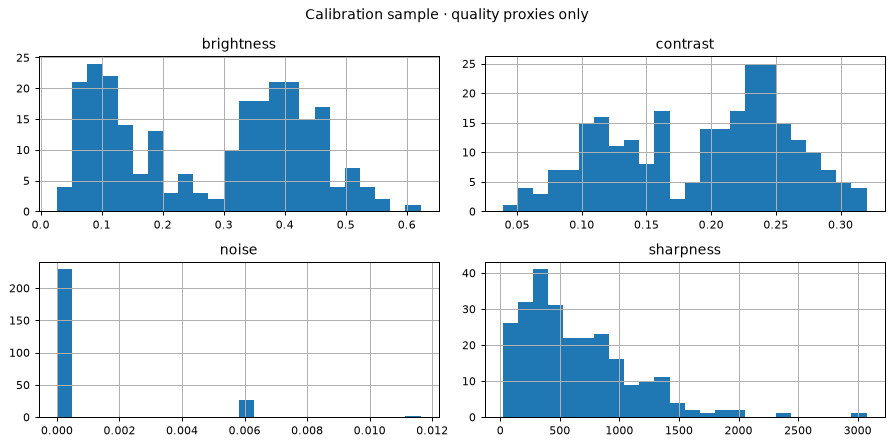

Calibration uses a bounded seeded sample, not every calibration frame.
At most one filter; fixed priority Gamma, CLAHE, Denoise, Sharpen, otherwise skip.
Quality loss is a heuristic proxy; lower loss does not prove higher detection AP.
Small candidate support can miss adverse cases; inspect paired pilot examples.
Minimum support is an engineering gate, not a statistical adequacy guarantee.
Noise proxy is unvalidated and can collapse to zero; unsupported routes stay off.
No development-validation or final-test outcome enters recipe fitting.


In [4]:
policy_path = RUN_ROOT / "policy.json"
if policy_path.exists():
    policy = validate_policy(read_json(policy_path), protocol)
    assert (
        policy["seed"],
        policy["sample_size"],
        policy["per_operator"],
        policy["minimum_support"],
    ) == (
        SEED,
        CALIBRATION_SAMPLE,
        PER_OPERATOR,
        MIN_SUPPORT,
    )
else:
    policy = calibrate_policy(
        protocol,
        DATA_ROOT,
        seed=SEED,
        sample_size=CALIBRATION_SAMPLE,
        per_operator=PER_OPERATOR,
        min_support=MIN_SUPPORT,
    )
freeze_policy(policy_path, policy, protocol)
print("Frozen policy before pilot inspection:", policy["policy_id"])
display(policy["recipes"])
display(
    pd.DataFrame(policy["route_support"]).T[
        ["eligible_count", "candidate_count", "minimum_support", "status"]
    ]
)
display(policy["noise_diagnostics"])
display(pd.DataFrame(policy["candidates"]))
calibration = pd.DataFrame(policy["measurements"])
calibration[list(METRICS[:4])].hist(bins=24, figsize=(10, 5))
plt.suptitle("Calibration sample · quality proxies only")
plt.tight_layout()
plt.savefig(REPORT_ROOT / "calibration_quality.png")
plt.show()
print("\n".join(policy["limits"]))

## Budget storage, convert once, export exactly Raw and Adaptive

Estimate from an evenly spaced selected-training sample using the frozen recipe.
Use the p90 image-size estimate plus 25% headroom and 1 GiB for labels/conversion.
This is an estimate, not a worst-case bound. Only the selected subset is exported;
S20/S40 do not materialize automatically. Sources stay unchanged. Labels are converted
once through the official stack with 0.01-pixel source-box roundtrip assertions, then
copied byte-for-byte. Pair identity pins the protocol, subset, policy and exporter.
Neither branch contains development-validation or final-test images.

In [5]:
records, _, sources = scan_bdd(DATA_ROOT, strict=False)
for split, source in sources.items():
    assert source["sha256"] == protocol["annotation_sources"][split]["sha256"]
partitions = training_records(protocol, subsets, EXPORT_SUBSET, records, DATA_ROOT)
selected = partitions["train"]
sample = [selected[i] for i in np.linspace(0, len(selected) - 1, min(16, len(selected)), dtype=int)]
budget = estimate_disk(sample, len(selected), ["raw_reencoded", "adaptive"], policy["recipes"])
budget.to_csv(REPORT_ROOT / "storage_estimate.csv", index=False)
required = float(budget.p90_budget_GiB.sum() * 1.25 + 1)
free = shutil.disk_usage(RUN_ROOT).free / 2**30
display(budget)
print(f"Estimated headroom requirement {required:.2f} GiB; free {free:.2f} GiB")
assert free >= required, "Insufficient estimated storage; do not start the export"
converted = RUN_ROOT / "conversion" / EXPORT_SUBSET
with capture_output() as conversion_log:
    conversion = convert_labels(partitions, converted, convention="continuous")
(RUN_ROOT / f"{EXPORT_SUBSET}_conversion.log").write_text(
    conversion_log.stdout + conversion_log.stderr
)
pair_root = RUN_ROOT / "datasets" / EXPORT_SUBSET
tables = export_pair(partitions, converted, pair_root, policy, protocol, subsets, EXPORT_SUBSET)
assert verify_alignment([pair_root / b for b in tables]) == len(selected)
for branch in tables:
    assert not list((pair_root / branch / "images/test").iterdir())
    assert not list((pair_root / branch / "images/tune").iterdir())
print("Deep-verified paired images per branch:", len(selected))

,variant,sample_images,planned_images,mean_bytes_per_image,estimated_GiB,p90_budget_GiB
0,raw_reencoded,16,4890,145261.875,0.661547,0.832884
1,adaptive,16,4890,145261.875,0.661547,0.832884


Estimated headroom requirement 3.08 GiB; free 764.55 GiB


Deep-verified paired images per branch: 4890


## Paired JPEG quality, routing and offline cost

Before/after below compares the **decoded exported Raw JPEG95** and **Adaptive JPEG95**.
Signed deltas expose adverse changes; higher brightness, contrast or sharpness alone
is not success. Policy decisions use image pixels only. Environmental labels are joined
**after freeze** for descriptive subgroup analysis. Preprocessing times include metric
extraction and filtering on CPU, exclude decode/encode/write, and retain their original
measurement on export reuse. Report full preparation separately. These are offline
costs on this machine, not detector or end-to-end deployment latency.

decision
skip     3783
gamma    1107
Name: images, dtype: int64

Skip rate: 0.7736196319018405
Filter counts: {0: 3783, 1: 1107}


,branch,stage,mean_ms,p50_ms,p95_ms
0,raw,preprocess_ms,2.827606,2.779504,3.223847
1,raw,preparation_ms,7.472327,7.431650,8.825413
2,adaptive,preprocess_ms,3.551277,2.915488,5.979977
3,adaptive,preparation_ms,8.335910,7.974135,10.304035


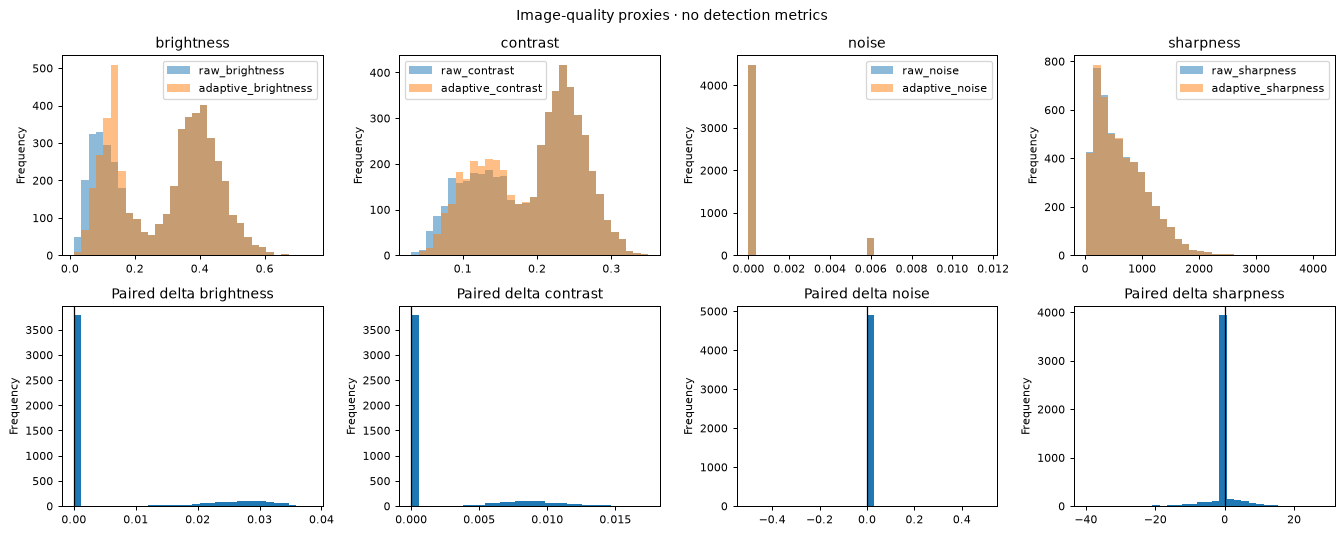

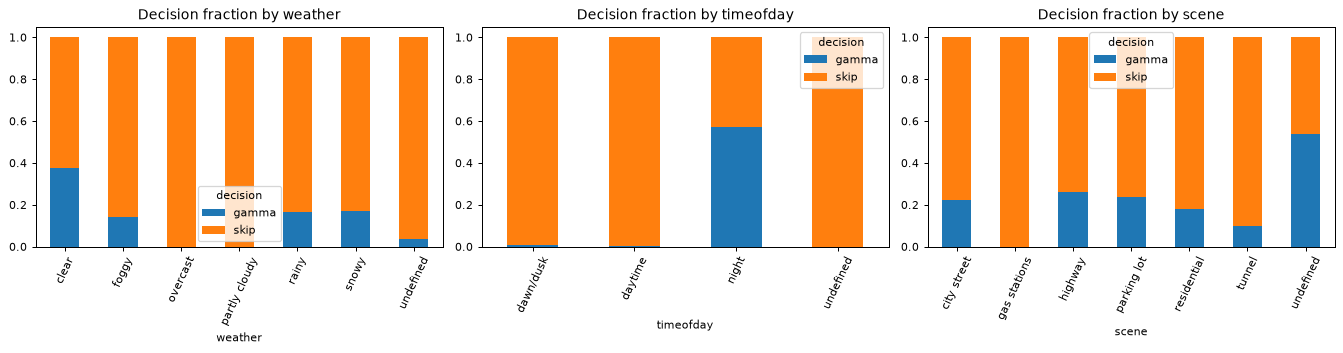

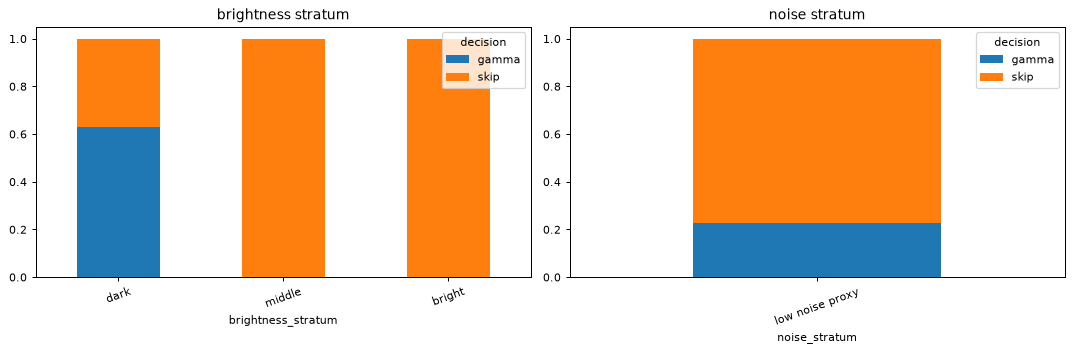

,count,mean,min,max
decision,,,,
gamma,1107,-0.239747,-0.970469,-0.031107
skip,3783,0.000000,0.000000,0.000000


In [6]:
paired = paired_quality(pair_root)
paired.to_csv(pair_root / "paired_quality.csv", index=False)
meta = tables["adaptive"].copy()
meta["filters"] = meta.decisions.map(len)
meta["decision"] = meta.decisions.map(lambda d: d[0]["name"] if d else "skip")
assert meta.filters.max() <= 1
attributes = pd.DataFrame([{"id": r["id"], **r["attributes"]} for r in pool])
analysis = paired.merge(
    meta[["id", "decision", "filters", "preprocess_ms", "preparation_ms"]],
    on="id",
    validate="one_to_one",
).merge(attributes, on="id", validate="one_to_one")
analysis["brightness_stratum"] = pd.cut(
    analysis.raw_brightness,
    [0, 0.2, 0.4, 1],
    labels=["dark", "middle", "bright"],
    include_lowest=True,
)
analysis["noise_stratum"] = np.where(analysis.raw_noise > 0.035, "noisy proxy", "low noise proxy")
analysis.to_csv(pair_root / "analysis.csv", index=False)
display(analysis.decision.value_counts().rename("images"))
print("Skip rate:", float((analysis.decision == "skip").mean()))
print("Filter counts:", analysis.filters.value_counts().to_dict())
latency = pd.DataFrame(
    [
        {
            "branch": b,
            "stage": stage,
            "mean_ms": t[stage].mean(),
            "p50_ms": t[stage].quantile(0.5),
            "p95_ms": t[stage].quantile(0.95),
        }
        for b, t in tables.items()
        for stage in ["preprocess_ms", "preparation_ms"]
    ]
)
display(latency)
latency.to_csv(REPORT_ROOT / "offline_latency.csv", index=False)
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, metric in enumerate(METRICS[:4]):
    analysis[[f"raw_{metric}", f"adaptive_{metric}"]].plot.hist(
        ax=axes[0, j], bins=32, alpha=0.5, title=metric
    )
    analysis[f"delta_{metric}"].plot.hist(ax=axes[1, j], bins=32, title=f"Paired delta {metric}")
    axes[1, j].axvline(0, color="black", linewidth=1)
fig.suptitle("Image-quality proxies · no detection metrics")
fig.tight_layout()
fig.savefig(REPORT_ROOT / "paired_quality.png")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, axis in zip(axes, ["weather", "timeofday", "scene"], strict=True):
    pd.crosstab(analysis[axis], analysis.decision, normalize="index").plot.bar(
        stacked=True, ax=ax, title=f"Decision fraction by {axis}", rot=65
    )
fig.tight_layout()
fig.savefig(REPORT_ROOT / "routing_environment.png")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, axis in zip(axes, ["brightness_stratum", "noise_stratum"], strict=True):
    pd.crosstab(analysis[axis], analysis.decision, normalize="index").plot.bar(
        stacked=True, ax=ax, title=axis.replace("_", " "), rot=20
    )
fig.tight_layout()
fig.savefig(REPORT_ROOT / "routing_quality.png")
plt.show()
display(analysis.groupby("decision").proxy_loss_delta.agg(["count", "mean", "min", "max"]))

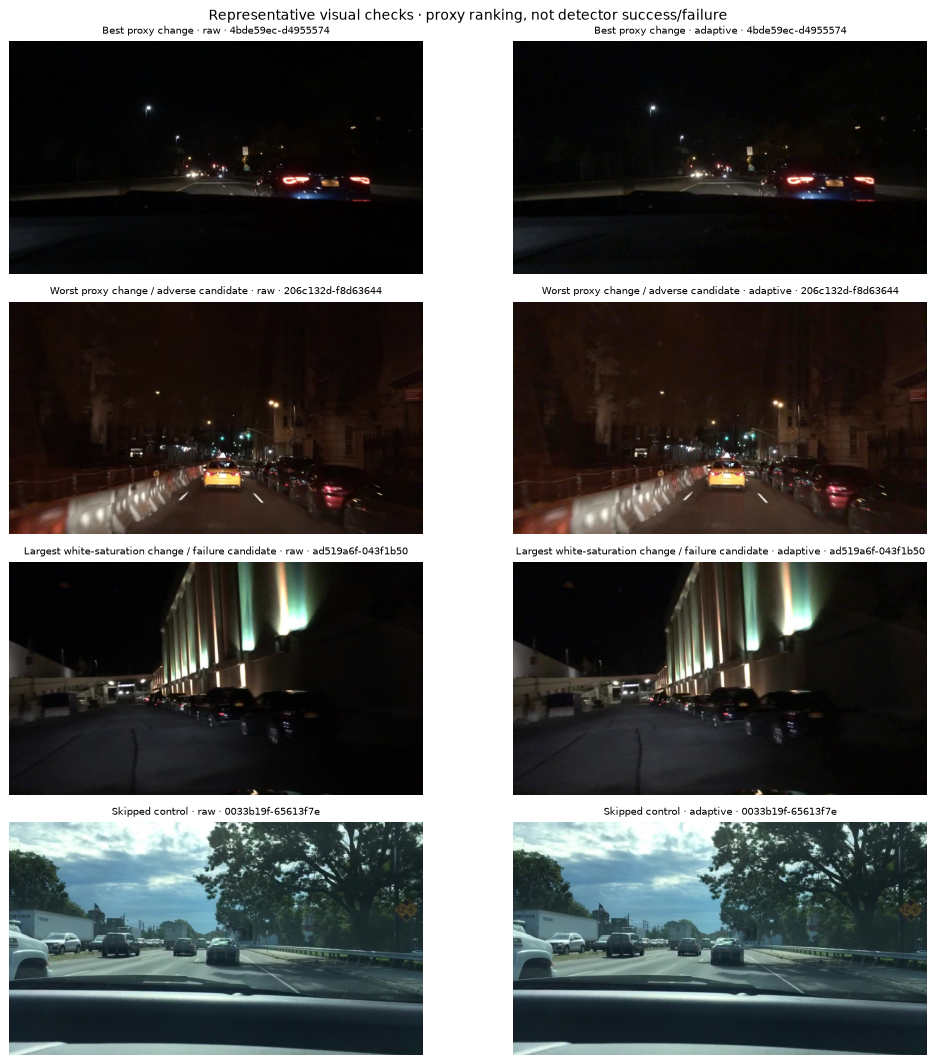

In [7]:
changed = analysis[analysis.decision != "skip"].sort_values(["proxy_loss_delta", "id"])
examples = []
if len(changed):
    examples += [
        ("Best proxy change", changed.iloc[0]["id"]),
        ("Worst proxy change / adverse candidate", changed.iloc[-1]["id"]),
    ]
    clipping = changed.sort_values(["delta_white_fraction", "id"])
    examples += [("Largest white-saturation change / failure candidate", clipping.iloc[-1]["id"])]
skipped = analysis[analysis.decision == "skip"].sort_values("id")
if len(skipped):
    examples.append(("Skipped control", skipped.iloc[0]["id"]))
fig, axes = plt.subplots(len(examples), 2, figsize=(12, 3 * len(examples)), squeeze=False)
for i, (label, sample_id) in enumerate(examples):
    for j, branch in enumerate(["raw", "adaptive"]):
        row = tables[branch].set_index("id").loc[sample_id]
        axes[i, j].imshow(cv2.cvtColor(read_image(row.image), cv2.COLOR_BGR2RGB))
        axes[i, j].set_title(f"{label} · {branch} · {sample_id}", fontsize=8)
        axes[i, j].axis("off")
fig.suptitle("Representative visual checks · proxy ranking, not detector success/failure")
fig.tight_layout()
# Source-image examples stay gitignored; the notebook retains inline inspection evidence.
fig.savefig(pair_root / "examples.png")
plt.show()

## Save reproducible compact evidence

The complete immutable subset manifest and calibrated recipe remain under the run root.
Commit compressed training-pool/subset membership, the frozen small recipe, hashes,
support/quality/cost summaries and figures. Images and per-image large tables stay under
runs; final test stays untouched. S20 is ready for a later paired scaling decision.
Do not retune this recipe after inspecting downstream development results; a new
research decision requires a new version and disclosure.

In [8]:
subset_ids = {name: set(s["ids"]) for name, s in subsets["subsets"].items()}
membership = pd.DataFrame(
    [
        {
            "id": r["id"],
            "group": r["group"],
            **{name: r["id"] in subset_ids[name] for name, s in subsets["subsets"].items()},
        }
        for r in sorted(pool, key=lambda r: r["id"])
    ]
)
member_path = REPORT_ROOT / "subset_membership.csv.gz"
compressed = gzip.compress(membership.to_csv(index=False).encode(), mtime=0)
if member_path.exists() and member_path.read_bytes() != compressed:
    raise ValueError("Committed subset membership changed; choose a new version/root")
member_path.write_bytes(compressed)
write_json(REPORT_ROOT / "policy.json", policy)
summary = {
    "protocol_id": protocol["manifest_id"],
    "subsets_id": subsets["manifest_id"],
    "policy_id": policy["policy_id"],
    "policy_version": policy["version"],
    "route_support": policy["route_support"],
    "noise_diagnostics": policy["noise_diagnostics"],
    "membership_sha256": file_hash(member_path),
    "subsets": {
        name: {k: v for k, v in s.items() if k not in {"ids", "groups"}}
        for name, s in subsets["subsets"].items()
    },
    "materialized_subset": EXPORT_SUBSET,
    "images_per_branch": len(selected),
    "pair": read_json(pair_root / "pair.json"),
    "exports": {
        b: {
            "identity": read_json(pair_root / b / "export.json"),
            "verified": read_json(pair_root / b / "verified.json"),
        }
        for b in tables
    },
    "skip_rate": float((analysis.decision == "skip").mean()),
    "decisions": {k: int(v) for k, v in analysis.decision.value_counts().items()},
    "proxy_improved": int((analysis.proxy_loss_delta < -1e-8).sum()),
    "proxy_worsened": int((analysis.proxy_loss_delta > 1e-8).sum()),
    "mean_proxy_loss_delta": float(analysis.proxy_loss_delta.mean()),
    "examples": examples,
    "offline_latency": latency.to_dict("records"),
    "actual_image_GiB": {
        b: sum(Path(p).stat().st_size for p in t.image) / 2**30 for b, t in tables.items()
    },
    "environment": {
        "python": platform.python_version(),
        "opencv": cv2.__version__,
        "numpy": np.__version__,
        "cpu_count": os.cpu_count(),
        "opencv_threads": cv2.getNumThreads(),
        "machine": platform.machine(),
    },
    "final_test_pixels_accessed": False,
    "development_pixels_accessed": False,
    "detector_run": False,
    "training_run": False,
    "support_audit_sha256": file_hash(REPORT_ROOT / "subset_support.csv"),
    "paired_quality_sha256": file_hash(pair_root / "paired_quality.csv"),
    "limitations": policy["limits"] + subsets["limitations"],
}
write_json(REPORT_ROOT / "summary.json", summary)
print("PASS: nested immutable subsets; calibration-only frozen recipe; paired JPEG95 S10 exports")
display(
    pd.Series(
        {
            "S10": len(subsets["subsets"]["S10"]["ids"]),
            "S20": len(subsets["subsets"]["S20"]["ids"]),
            "Raw GiB": summary["actual_image_GiB"]["raw"],
            "Adaptive GiB": summary["actual_image_GiB"]["adaptive"],
        }
    )
)

PASS: nested immutable subsets; calibration-only frozen recipe; paired JPEG95 S10 exports


S10             4890.000000
S20             9781.000000
Raw GiB            0.568316
Adaptive GiB       0.579732
dtype: float64